# Main-model loss curves

Four panels for the models currently selected by the pipeline configs:
**Seeds → Simulations**, **Default → Thinner, denser branches**,
**Simulation → Experiment**, and **Synthetic patterns → seed**.

Run all cells with the `pytorch_pa_patternprediction` kernel. The plot uses
32-point Arial from the deterministic config, centered titles, no grids, and a
shared training/validation legend. ControlNet has training loss only. Figures
appear inline; optional PDF/PNG export is controlled by `EXPORT_FIGURES`.

No model weights are loaded, and no GPU, training, or inference is used.


In [1]:
%matplotlib inline
from pathlib import Path
import json
import re
import runpy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator

ROOT = Path('/hpc/dctrl/ks723/Physics_constrained_DL_pattern_prediction')
EXPORT_FIGURES = False
EXPORT_DIR = ROOT / 'source_data' / 'model_loss_curves'

# run_path keeps the three same-named config modules separate; no training imports.
CONFIG_FILES = {
    'deterministic': ROOT / 'seed_to_sim1_sim2_deterministic/utils/config.py',
    'controlnet': ROOT / 'sim_to_exp_diffusion/controlnet_essential/cldm/config.py',
    'inverse': ROOT / 'information_encoding_decoding/utils/config.py',
}
configs = {name: runpy.run_path(str(path)) for name, path in CONFIG_FILES.items()}

specs = [
    dict(key='seed_to_sim', title='Seeds → simulated patterns (Fig. 2)',
         config='deterministic', variable='MODEL_DILRESNET_FIG2', kind='resnet',
         ylabel='Latent MSE', scale='log'),
    dict(key='sim1_to_sim2', title='Simulation 1 → simulation 2 (Fig. 3)',
         config='deterministic', variable='MODEL_DILRESNET_FIG3', kind='resnet',
         ylabel='Latent MSE', scale='log'),
    dict(key='controlnet', title='Simulation → experiment: ControlNet (Fig. 5)',
         config='controlnet', variable='CKPT_PATH', kind='controlnet',
         ylabel='Diffusion loss', scale='linear'),
    dict(key='inverse', title='Generated patterns → seeds (Fig. 6)',
         config='inverse', variable='CKPT_PATH_MORESEEDS_DIFFUSION', kind='inverse',
         ylabel='Weighted BCE + 0.5 Dice', scale='linear'),

]
for spec in specs:
    spec['checkpoint'] = Path(configs[spec['config']][spec['variable']])

plt.rcParams.update({'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'pdf.fonttype': 42})
COLORS = {'training': '#2874A6', 'validation': '#D17A22'}

## Read the histories

- ResNet `test_losses` are **internal validation**, not independent-test loss.
- Inverse U-Net training losses were logged periodically by batch. The plotted
  training line is the **mean of logged batches within each epoch**, not an exact
  full-epoch mean; validation uses recorded epoch losses.
- Resumed inverse logs are combined with the initial run. Repeated epoch/step
  observations are replaced by their continuation-log versions.
- ControlNet has training epoch means and sampled training-step losses. A
  validation curve is shown only if a validation epoch series actually exists.
- All stored epochs and spikes remain visible; no smoothing or truncation is
  applied to the epoch plots. These are optimization histories, not SSIM/F1 curves.

In [2]:
from pathlib import Path as _DataPath
import sys as _data_sys
_DATA_ROOT = next(p for p in (_DataPath.cwd(), *_DataPath.cwd().parents) if (p / 'paper_paths.py').is_file())
if str(_DATA_ROOT) not in _data_sys.path: _data_sys.path.insert(0, str(_DATA_ROOT))
from paper_paths import figure_source_path as _figure_source_path
def resnet_history(spec):
    checkpoint = spec['checkpoint']
    # Remove checkpoint-selection suffixes, not the unique run identifier.
    stem = re.sub(r'_(?:best_tolerant|best|last)$', '', checkpoint.stem)
    path = Path(configs['deterministic']['LOGS_SAVE_LOCATION']) / f'losses_{stem}.json'
    data = json.loads(path.read_text())
    if len(data['train_losses']) != len(data['test_losses']):
        raise ValueError(f'Unequal training/validation history lengths: {path}')
    frame = pd.DataFrame({
        'epoch': np.arange(1, len(data['train_losses']) + 1),
        'training': data['train_losses'], 'validation': data['test_losses'],
    })
    # JSON histories do not store weight metadata. Annotate minimum separately.
    return dict(frame=frame, sources=[path], selected_epoch=None, step_frame=None,
                selection_note='ResNet checkpoint epoch is not stored in its JSON; minimum validation is marked separately.')


def inverse_history(spec):
    run_dir = spec['checkpoint'].parent.parent
    # The trainer names continuations <original-run>_resume<job-id>. Only merge
    # those siblings; never substitute a different learning rate or ablation run.
    # Run names contain literal square brackets; avoid treating them as glob syntax.
    resumed = sorted((path for path in run_dir.parent.iterdir()
                      if path.is_dir() and path.name.startswith(run_dir.name + '_resume')),
                     key=lambda path: (path.stat().st_mtime_ns, path.name))
    paths = [_figure_source_path(p / 'metrics.csv') for p in [run_dir, *resumed] if (_figure_source_path(p / 'metrics.csv')).is_file()]
    if not paths:
        raise FileNotFoundError(f'No CSV loss logs for configured checkpoint: {spec["checkpoint"]}')
    parts = []
    for order, path in enumerate(paths):
        raw = pd.read_csv(path)
        for series, column in [('training', 'train_loss'), ('validation', 'val_loss')]:
            if column not in raw:
                continue
            part = raw[['epoch', 'step', column]].copy()
            part.columns = ['epoch', 'step', 'loss']
            for column_name in ['epoch', 'step', 'loss']:
                part[column_name] = pd.to_numeric(part[column_name], errors='coerce')
            part = part.dropna(subset=['epoch', 'step', 'loss'])
            part['series'] = series
            part['source_order'] = order
            parts.append(part)
    if not parts:
        raise ValueError(f'No numeric loss records in {paths}')
    observations = pd.concat(parts, ignore_index=True)
    observations = observations.drop_duplicates(['series', 'epoch', 'step'], keep='last')
    training = observations[observations['series'] == 'training'].groupby('epoch')['loss'].mean()
    # If a resumed epoch was validated more than once, keep its latest record.
    validation = (observations[observations['series'] == 'validation']
                  .sort_values(['epoch', 'source_order', 'step'])
                  .drop_duplicates('epoch', keep='last').set_index('epoch')['loss'])
    frame = pd.concat([training.rename('training'), validation.rename('validation')], axis=1)
    frame = frame.sort_index().rename_axis('epoch').reset_index()
    frame['epoch'] = frame['epoch'].astype(int) + 1
    match = re.search(r'epoch[=\-](\d+)', spec['checkpoint'].name)
    selected = int(match.group(1)) + 1 if match else None
    if selected is not None and selected not in set(frame['epoch']):
        raise ValueError(f'Configured checkpoint epoch {selected} is missing from the recovered logs: {paths}')
    return dict(frame=frame, sources=paths, selected_epoch=selected, step_frame=None,
                selection_note='Checkpoint epoch read from configured filename (converted to one-based numbering).')


def controlnet_history(spec):
    run_dir = spec['checkpoint'].parent.parent
    events = sorted(run_dir.glob('events.out.tfevents*'))
    if not events:
        raise FileNotFoundError(f'No TensorBoard events beside configured ControlNet checkpoint: {run_dir}')
    accumulator = EventAccumulator(str(run_dir), size_guidance={'scalars': 0})
    accumulator.Reload()
    tags = accumulator.Tags()['scalars']
    epoch_events = accumulator.Scalars('epoch') if 'epoch' in tags else []
    epoch_at_step = {event.step: int(event.value) + 1 for event in epoch_events}
    def epoch_series(tag):
        output = {}
        for event in accumulator.Scalars(tag):
            if event.step not in epoch_at_step:
                raise ValueError(f'No recorded epoch at step {event.step} for {tag}')
            output[epoch_at_step[event.step]] = event.value
        return pd.Series(output, dtype=float)
    train_tag = next((tag for tag in ['train/loss_epoch', 'train/loss_simple_epoch'] if tag in tags), None)
    if train_tag is None:
        raise ValueError(f'No training epoch-loss tag in {run_dir}; available tags: {tags}')
    series = {'training': epoch_series(train_tag)}
    val_tag = next((tag for tag in ['val/loss', 'val/loss_epoch', 'val/loss_simple', 'val/loss_simple_epoch'] if tag in tags), None)
    if val_tag:
        series['validation'] = epoch_series(val_tag)
    frame = pd.DataFrame(series).sort_index().rename_axis('epoch').reset_index()
    step_frame = None
    if 'train/loss_step' in tags:
        step_events = accumulator.Scalars('train/loss_step')
        step_frame = pd.DataFrame({'step': [e.step for e in step_events],
                                   'training': [e.value for e in step_events]})
    match = re.search(r'epoch[=\-](\d+)', spec['checkpoint'].name)
    selected = int(match.group(1)) + 1 if match else None
    return dict(frame=frame, sources=events, selected_epoch=selected, step_frame=step_frame,
                selection_note=f'Loss tag: {train_tag}. No validation line is fabricated.')


histories = {}
for spec in specs:
    if not spec['checkpoint'].is_file():
        raise FileNotFoundError(f'Configured checkpoint does not exist: {spec["checkpoint"]}')
    reader = {'resnet': resnet_history, 'inverse': inverse_history, 'controlnet': controlnet_history}[spec['kind']]
    histories[spec['key']] = reader(spec)

summary_rows = []
for spec in specs:
    history = histories[spec['key']]
    frame = history['frame']
    summary_rows.append({
        'Model': spec['title'], 'Config variable': spec['variable'],
        'Epochs with training loss': int(frame['training'].notna().sum()),
        'Epochs with validation loss': int(frame.get('validation', pd.Series(dtype=float)).notna().sum()),
        'Configured checkpoint epoch (1-based)': history['selected_epoch'],
    })
summary = pd.DataFrame(summary_rows)
display(summary.style.hide(axis='index'))
for spec in specs:
    history = histories[spec['key']]
    print(f'\n{spec["title"]}\n  config: {CONFIG_FILES[spec["config"]]}')
    print(f'  checkpoint: {spec["checkpoint"]}')
    for source in history['sources']:
        print(f'  loss source: {source}')

Model,Config variable,Epochs with training loss,Epochs with validation loss,Configured checkpoint epoch (1-based)
Seeds → simulated patterns (Fig. 2),MODEL_DILRESNET_FIG2,500,500,nan
Simulation 1 → simulation 2 (Fig. 3),MODEL_DILRESNET_FIG3,417,417,nan
Simulation → experiment: ControlNet (Fig. 5),CKPT_PATH,5,0,5.000000
Generated patterns → seeds (Fig. 6),CKPT_PATH_MORESEEDS_DIFFUSION,193,193,143.000000



Seeds → simulated patterns (Fig. 2)
  config: /hpc/dctrl/ks723/Physics_constrained_DL_pattern_prediction/seed_to_sim1_sim2_deterministic/utils/config.py
  checkpoint: /hpc/group/youlab/ks723/miniconda3/saved_models/trained/Pixel_32x32x3to32x32x4_dilRESNET_30k_graypatterns_seedtointermediate_v101_4-1759366230_best.pt
  loss source: /hpc/group/youlab/ks723/miniconda3/saved_models/logs/losses_Pixel_32x32x3to32x32x4_dilRESNET_30k_graypatterns_seedtointermediate_v101_4-1759366230.json

Simulation 1 → simulation 2 (Fig. 3)
  config: /hpc/dctrl/ks723/Physics_constrained_DL_pattern_prediction/seed_to_sim1_sim2_deterministic/utils/config.py
  checkpoint: /hpc/group/youlab/ks723/miniconda3/saved_models/trained/Pixel_32x32x3to32x32x4_dilRESNET_graypatterns_intermediatetocomplex_Model_30000_v102_9-1759430803.pt
  loss source: /hpc/group/youlab/ks723/miniconda3/saved_models/logs/losses_Pixel_32x32x3to32x32x4_dilRESNET_graypatterns_intermediatetocomplex_Model_30000_v102_9-1759430803.json

Simulatio

## Four-panel loss figure

All recorded epochs are retained without smoothing. ResNet validation losses use
a logarithmic scale; ControlNet and inverse-decoder losses use a linear scale.
The shared legend applies to all panels, but ControlNet has no recorded
validation curve. Its epoch axis extends to 6 and its loss axis to 0.11 so the
five recorded points have space around them.

`EPOCH_AXIS` controls the orientation; the default keeps epochs horizontal.


Thin light-gray dashed lines mark the epoch with the lowest recorded validation loss. ControlNet has no validation marker. These lines do not imply that every configured checkpoint was selected at that epoch.

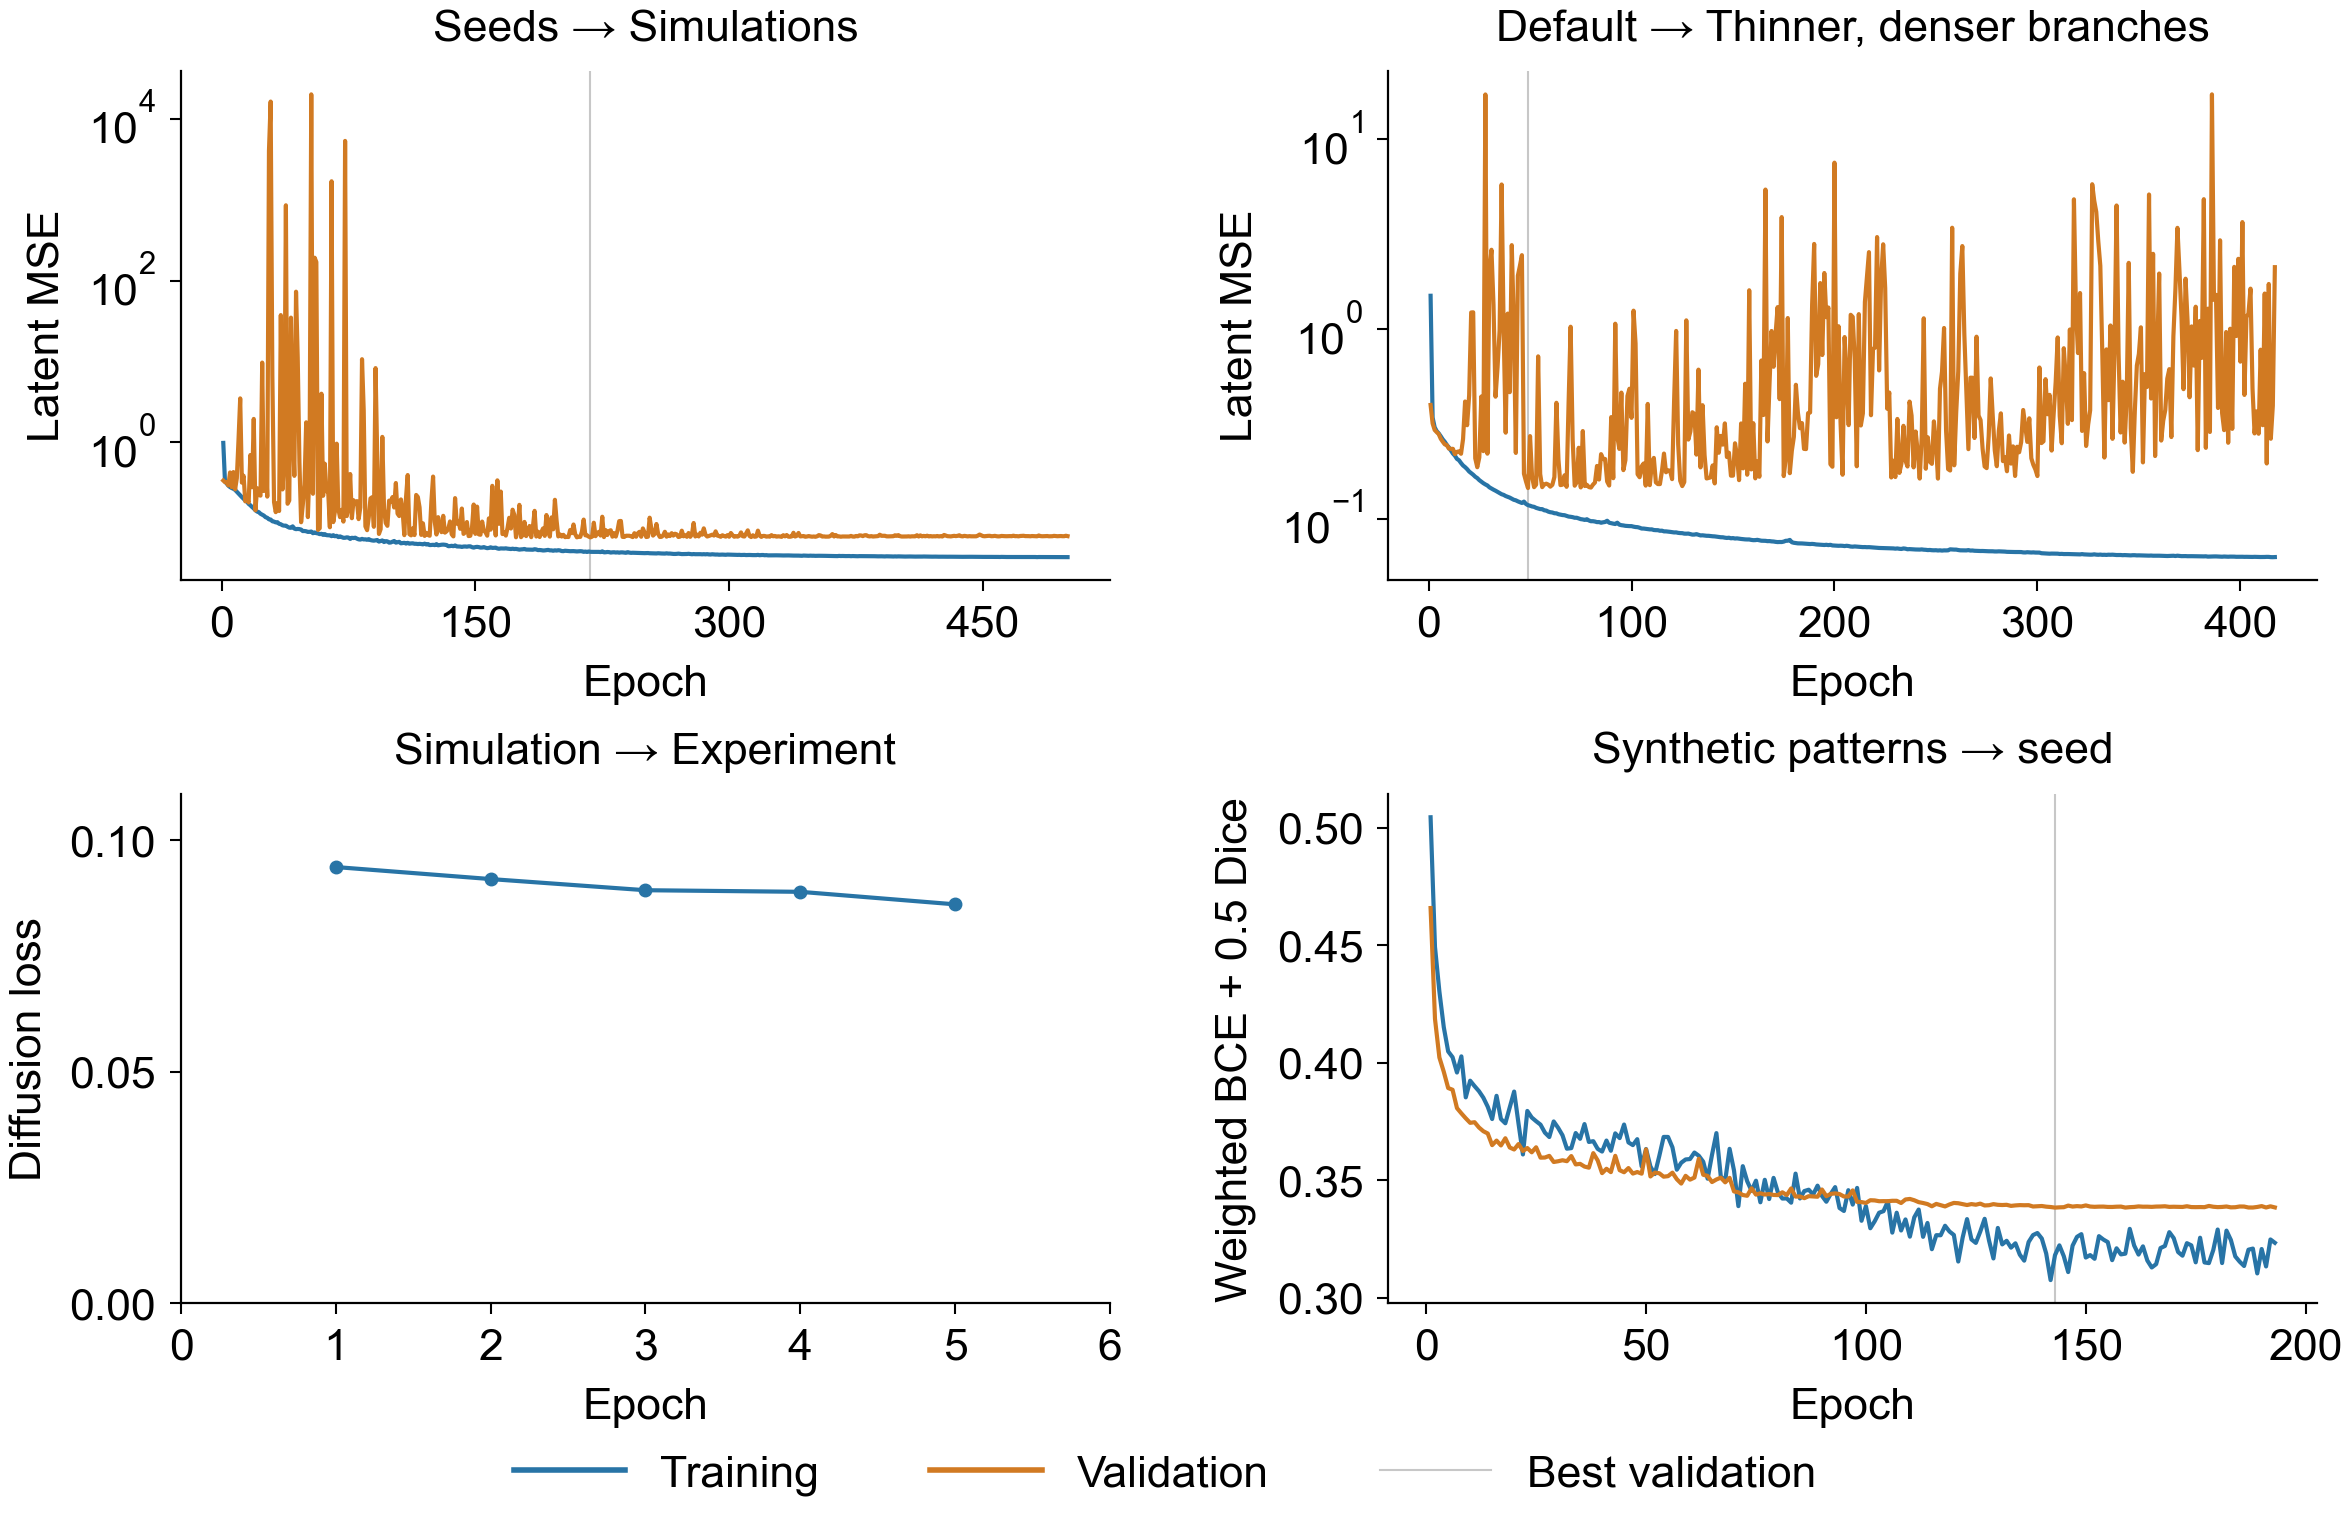

In [10]:
from matplotlib import font_manager
from matplotlib.lines import Line2D
from matplotlib.ticker import MaxNLocator, NullLocator

# Use the exact Arial font file referenced by the deterministic pipeline config.
FONT_PATH = Path(configs['deterministic']['FPATH'])
if not FONT_PATH.is_file():
    raise FileNotFoundError(f'Configured Arial font does not exist: {FONT_PATH}')
font_manager.fontManager.addfont(str(FONT_PATH))
FONT_NAME = font_manager.FontProperties(fname=str(FONT_PATH)).get_name()
FONT_SIZE = 32
EPOCH_AXIS = 'x'  # Change to 'y' to transpose all four panels.

panel_titles = [
    'Seeds → Simulations',
    'Default → Thinner, denser branches',
    'Simulation → Experiment',
    'Synthetic patterns → seed',
]

style = {
    'font.family': FONT_NAME,
    'font.size': FONT_SIZE,
    'axes.titlesize': FONT_SIZE,
    'axes.labelsize': FONT_SIZE,
    'xtick.labelsize': FONT_SIZE,
    'ytick.labelsize': FONT_SIZE,
    'legend.fontsize': FONT_SIZE,
    'axes.grid': False,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.linewidth': 1.6,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
}

with plt.rc_context(style):
    fig, axes = plt.subplots(2, 2, figsize=(24, 16))
    for spec, title, ax in zip(specs[:4], panel_titles, axes.flat):
        frame = histories[spec['key']]['frame']
        for series in ['training', 'validation']:
            if series not in frame or frame[series].dropna().empty:
                continue
            values = frame.dropna(subset=[series])
            x, y = values['epoch'], values[series]
            if EPOCH_AXIS == 'y':
                x, y = y, x
            ax.plot(x, y, color=COLORS[series], linewidth=3,
                    marker='o' if spec['kind'] == 'controlnet' else None,
                    markersize=9)

        # Thin gray line marks the epoch with minimum recorded validation loss.
        if 'validation' in frame and frame['validation'].notna().any():
            best_row = frame.loc[frame['validation'].idxmin()]
            best_epoch = int(best_row['epoch'])
            if EPOCH_AXIS == 'x':
                ax.axvline(best_epoch, color='#bdbdbd', linewidth=1.5,
                           linestyle='-', alpha=0.85, zorder=0)
            else:
                ax.axhline(best_epoch, color='#bdbdbd', linewidth=1.5,
                           linestyle='-', alpha=0.85, zorder=0)

        ax.set_title(title, loc='center', pad=22)
        if EPOCH_AXIS == 'x':
            ax.set_xlabel('Epoch', labelpad=14)
            ax.set_ylabel(spec['ylabel'], labelpad=14)
            ax.set_yscale(spec['scale'])
            ax.xaxis.set_major_locator(MaxNLocator(nbins=5, integer=True))
        elif EPOCH_AXIS == 'y':
            ax.set_ylabel('Epoch', labelpad=14)
            ax.set_xlabel(spec['ylabel'], labelpad=14)
            ax.set_xscale(spec['scale'])
            ax.yaxis.set_major_locator(MaxNLocator(nbins=5, integer=True))
        else:
            raise ValueError("EPOCH_AXIS must be 'x' or 'y'.")

        if spec['kind'] == 'controlnet':
            if EPOCH_AXIS == 'x':
                ax.set_xlim(0, 6)
                ax.set_xticks(range(0, 7))
                ax.set_ylim(0, 0.11)
                ax.set_yticks([0, 0.05, 0.10])
            else:
                ax.set_ylim(0, 6)
                ax.set_yticks(range(0, 7))
                ax.set_xlim(0, 0.11)
                ax.set_xticks([0, 0.05, 0.10])
        ax.grid(False, which='both')
        ax.tick_params(axis='both', which='major', length=8, width=1.5, pad=10)
        if spec['scale'] == 'log':
            (ax.yaxis if EPOCH_AXIS == 'x' else ax.xaxis).set_minor_locator(NullLocator())

    handles = [Line2D([0], [0], color=COLORS[series], linewidth=4,
                      label=series.capitalize()) for series in ['training', 'validation']]
    handles.append(Line2D([0], [0], color='#bdbdbd', linewidth=1.5,
                          linestyle='-', alpha=0.85, label='Best validation'))
    fig.legend(handles=handles, loc='lower center', bbox_to_anchor=(0.5, 0.015),
               ncol=3, frameon=False, handlelength=2.5, columnspacing=2.5)
    fig.subplots_adjust(left=0.09, right=0.98, top=0.93, bottom=0.16,
                        wspace=0.30, hspace=0.42)
    if EXPORT_FIGURES:
        EXPORT_DIR.mkdir(parents=True, exist_ok=True)
        fig.savefig(EXPORT_DIR / 'main_figures_loss_overview.pdf', bbox_inches='tight')
        fig.savefig(EXPORT_DIR / 'main_figures_loss_overview.png', dpi=200, bbox_inches='tight')
    plt.show()
    plt.close(fig)


In [ ]:
from pathlib import Path as _ExportPath
import sys as _export_sys
_EXPORT_ROOT = next(p for p in (_ExportPath.cwd(), *_ExportPath.cwd().parents)
                    if (p / 'figure_exports').is_dir())
if str(_EXPORT_ROOT) not in _export_sys.path:
    _export_sys.path.insert(0, str(_EXPORT_ROOT))
import figure_exports as _figure_exports
# Vector PDF export: Supp. Fig. 25 — four model loss histories
# Run immediately after the preceding plotting/analysis cell.
from pathlib import Path
import runpy as _vector_runpy

# Locate the project from the notebook working directory; no sys.path changes.
VECTOR_PROJECT_ROOT = next(
    _p for _p in (Path.cwd(), *Path.cwd().parents)
    if (_p / 'figure_exports').is_dir()
)
save_vector_pdf = vars(_figure_exports)['save_vector_pdf']
VECTOR_DIR = VECTOR_PROJECT_ROOT / 'information_encoding_decoding' / 'vector based plots'

# The original fig remains usable after plt.close(fig).
save_vector_pdf(fig, VECTOR_DIR / 'SuppFig25_all_loss_curves.pdf')
_vector_loss_panels = [
    ('A', 'deterministic', 'seed_to_sim'),
    ('B', 'deterministic', 'sim1_to_sim2'),
    ('C', 'diffusion', 'controlnet'),
    ('D', 'inverse', 'inverse_decoder'),
]
_vector_sections = {
    'deterministic': 'seed_to_sim1_sim2_deterministic',
    'diffusion': 'sim_to_exp_diffusion',
    'inverse': 'information_encoding_decoding',
}
for _axis, (_letter, _section, _model_name) in zip(axes.flat, _vector_loss_panels):
    # Give each standalone panel the original shared legend as well.
    _legend = _axis.legend(handles=handles, loc='upper center',
                           bbox_to_anchor=(0.5, -0.25), ncol=1,
                           frameon=False, fontsize=FONT_SIZE)
    try:
        save_vector_pdf(
            fig, VECTOR_PROJECT_ROOT / _vector_sections[_section] / 'vector based plots'
            / f'SuppFig25{_letter}_{_model_name}_loss.pdf', panel=_axis,
        )
    finally:
        _legend.remove()


## Numerical summary at the configured checkpoints

This summary keeps **minimum validation loss** distinct from the loss at the
configured checkpoint. Selected epochs for `.ckpt` files come from their filenames;
ResNet JSON files do not prove the checkpoint epoch. Historical DDP reduction and
split provenance are not re-audited here. No independent-test loss is inferred.

In [4]:
from pathlib import Path as _DataPath
import sys as _data_sys
_DATA_ROOT = next(p for p in (_DataPath.cwd(), *_DataPath.cwd().parents) if (p / 'paper_paths.py').is_file())
if str(_DATA_ROOT) not in _data_sys.path: _data_sys.path.insert(0, str(_DATA_ROOT))
from paper_paths import figure_source_path as _figure_source_path
loss_rows = []
for spec in specs:
    history = histories[spec['key']]
    frame = history['frame']
    row = {'Model': spec['title'], 'Last logged epoch': int(frame['epoch'].max())}
    validation = frame.dropna(subset=['validation']) if 'validation' in frame else pd.DataFrame()
    if not validation.empty:
        best = validation.loc[validation['validation'].idxmin()]
        row['Minimum validation loss'] = best['validation']
        row['Minimum validation epoch'] = int(best['epoch'])
    epoch = history['selected_epoch']
    if epoch is not None:
        selected = frame[frame['epoch'] == epoch]
        row['Configured epoch'] = epoch
        if not selected.empty:
            row['Training loss at configured epoch'] = selected.iloc[-1]['training']
            row['Validation loss at configured epoch'] = selected.iloc[-1].get('validation', np.nan)
    loss_rows.append(row)
display(pd.DataFrame(loss_rows).style.hide(axis='index').format(precision=6, na_rep='—'))
if EXPORT_FIGURES:
    summary.to_csv(_figure_source_path(EXPORT_DIR / 'configured_model_sources_summary.csv'), index=False)
    pd.concat([history['frame'].assign(model=key) for key, history in histories.items()],
              ignore_index=True).to_csv(_figure_source_path(EXPORT_DIR / 'configured_epoch_losses.csv'), index=False)

Model,Last logged epoch,Minimum validation loss,Minimum validation epoch,Configured epoch,Training loss at configured epoch,Validation loss at configured epoch
Seeds → simulated patterns (Fig. 2),500,0.066881,218.000000,—,—,—
Simulation 1 → simulation 2 (Fig. 3),417,0.145805,49.000000,—,—,—
Simulation → experiment: ControlNet (Fig. 5),5,—,—,5.000000,0.086189,—
Generated patterns → seeds (Fig. 6),193,0.338379,143.000000,143.000000,0.318149,0.338379
